# **¿LOGRARAN LLEGAR A LA CIMA DEL EVEREST?**

### Información General
**Número de Grupo:** 7

**Integrantes:**
*   94696, Heiland Valentina Abril
*   95196, Pugliese Lourdes Belen
*   94822, Mendez Agustin Alberto
*   400148, de la Cuesta Luján
*   406644, Castigliano Federica
*   401156, Mamud Savina
* 403938, Bertuzzi Valentin
* 96121, Latorre Luka


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Introducción
El objetivo del proyecto es desarrollar un modelo de ciencia de datos supervisada capaz de predecir si un escalador logrará llegar a la cima del Everest.
La característica principal del problema es que se trata de una predicción **ex ante**: la predicción debe realizarse antes de comenzar la expedición. Por lo tanto, solo pueden utilizarse variables que representen información disponible en ese momento, como características del escalador, experiencia previa y planificación de la expedición.

La variable objetivo es:
- `summited = 1`: el escalador llegó a la cima.
- `summited = 0`: el escalador no llegó a la cima.

El dataset contiene información sobre 45.000 expediciones y 25 variables.

Objetivos de esta etapa:
1. Comprender las variables disponibles y su significado.
2. Analizar la calidad de los datos mediante estadísticas y gráficos.
3. Detectar valores nulos, duplicados, errores e inconsistencias.
4. Identificar valores extremos y decidir si deben conservarse o tratarse.
5. Eliminar variables que no sean útiles o que produzcan fuga de información (data leakage).
6. Transformar las variables categóricas a una representación numérica.
7. Preparar un dataset final limpio y listo para modelar.

# PARTE 1: PREPARACION

## 1.1 Librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

sns.set_theme(style="whitegrid")

## 1.2 Carga del dataset

In [ ]:
#import os
#os.listdir('/content')
#df = pd.read_csv('/content/everest_summit_master.csv')

!gdown 1JYjqJunZ7XE_VRwczX2-Lo6NygqIsNPZ -O everest_summit_master.csv

df = pd.read_csv('everest_summit_master.csv')


Downloading...
From: https://drive.google.com/uc?id=1JYjqJunZ7XE_VRwczX2-Lo6NygqIsNPZ
To: /content/everest_summit_master.csv
100% 5.21M/5.21M [00:00<00:00, 28.6MB/s]


# 4. Diccionario de variables

La interpretación de las variables se realiza según el significado de sus nombres y el dominio del problema.

| Variable | Tipo | Significado |
|---|---|---|
| `climber_id` | Categórica/ID | Identificador único del escalador |
| `year` | Numérica | Año de la expedición |
| `season` | Categórica | Estación de la expedición |
| `route` | Categórica | Ruta utilizada |
| `age` | Numérica | Edad del escalador |
| `sex` | Categórica | Sexo del escalador |
| `is_hired_staff` | Binaria | Indica si es personal contratado de alta montaña |
| `years_climbing` | Numérica | Años de experiencia en escalada |
| `prior_8000m_peaks` | Numérica | Cantidad de ochomiles ascendidos previamente |
| `prior_everest_attempts` | Numérica | Intentos previos en Everest |
| `highest_prev_altitude_m` | Numérica | Mayor altitud alcanzada previamente |
| `operator_tier` | Categórica | Categoría del operador de la expedición |
| `team_size` | Numérica | Tamaño del equipo |
| `sherpa_ratio` | Numérica | Relación de apoyo Sherpa respecto del equipo |
| `uses_oxygen` | Binaria | Uso planificado de oxígeno suplementario |
| `o2_start_altitude_m` | Numérica | Altitud prevista para comenzar el uso de oxígeno |
| `days_acclimatizing` | Numérica | Días planificados de aclimatación |
| `camps_established` | Numérica | Cantidad de campamentos establecidos |
| `summit_window_days` | Numérica | Cantidad de días disponibles en la ventana de cumbre |
| `weather_score` | Numérica | Puntaje de condiciones meteorológicas |
| `jetstream_risk` | Numérica | Nivel de riesgo asociado al jet stream |
| `queue_minutes_above_8000` | Numérica | Tiempo estimado de espera sobre 8.000 m |
| `turnaround_reason` | Categórica | Motivo por el que se dio la vuelta |
| `serious_incident` | Binaria | Indica si ocurrió un incidente grave |
| `summited` | Binaria | Indica si alcanzó la cima. **Variable objetivo** |



# 5. Análisis inicial de la estructura
Antes de modificar los datos, se realiza una inspección general para conocer:
- cantidad de registros y variables;
- tipos de datos;
- cantidad de valores distintos;
- presencia de valores nulos;
- estadísticas descriptivas;
- posibles problemas de calidad.

Es importante realizar este análisis antes de limpiar, para poder justificar posteriormente qué modificaciones fueron realizadas.

In [ ]:
# Resumen de calidad
resumen_calidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_unicos": df.nunique(dropna=False),
    "nulos": df.isna().sum(),
    "%_nulos": (df.isna().mean() * 100).round(2)
})

display(resumen_calidad)

,tipo,valores_unicos,nulos,%_nulos
climber_id,object,45000,0,0.0
year,int64,37,0,0.0
season,object,4,0,0.0
route,object,3,0,0.0
age,int64,61,0,0.0
sex,object,2,0,0.0
is_hired_staff,int64,2,0,0.0
years_climbing,int64,36,0,0.0
prior_8000m_peaks,int64,12,0,0.0
prior_everest_attempts,int64,4,0,0.0


# 6. Análisis de las variables categóricas

Primero se identifican las categorías posibles de cada variable no numérica. Esto permite detectar categorías inesperadas, errores de escritura o valores inconsistentes.

Además, se representa gráficamente la frecuencia de cada categoría.

### Resultado esperado del análisis categórico

En este dataset se observan las siguientes categorías:

- `season`: `spring`, `autumn`, `winter`, `summer`.
- `route`: `South Col-SE Ridge`, `North Ridge-NE`, `other`.
- `sex`: `M`, `F`.
- `operator_tier`: `budget`, `mid`, `premium`, `independent`.


No se observan valores nulos en estas variables ni categorías adicionales inesperadas.

# 7. Análisis de las variables numéricas

Para cada variable numérica se utilizarán:

- histograma: permite observar la distribución;
- boxplot: permite detectar valores extremos;
- countplot: se usa en variables discretas con pocos valores distintos para mostrar la frecuencia de cada valor.

La detección de valores extremos se realiza como una **herramienta de diagnóstico**, no como una regla automática para eliminar registros.

### Columna `year`


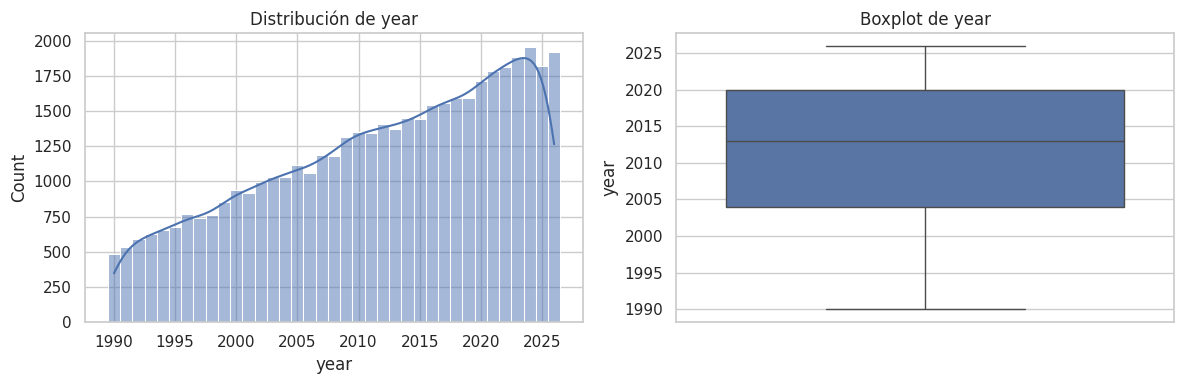

In [ ]:
col = "year"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma
sns.histplot(df[col], kde=True, discrete=True, ax=axes[0])
axes[0].set_title(f"Distribución de {col}")

# Boxplot
sns.boxplot(y=df[col], ax=axes[1])
axes[1].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

>Interpretacion: Las barras (histograma) muestran que la cantidad de expediciones al Everest fue aumentando con los años, teniendo su pico más alto en la última década (hacia 2020-2025).

>Sin valores extraños (Outliers): El gráfico de caja (boxplot) de la derecha muestra una distribución normal y limpia, sin valores atípicos absurdos (los años van lógicamente desde 1990 hasta 2025).


### Columna `season`

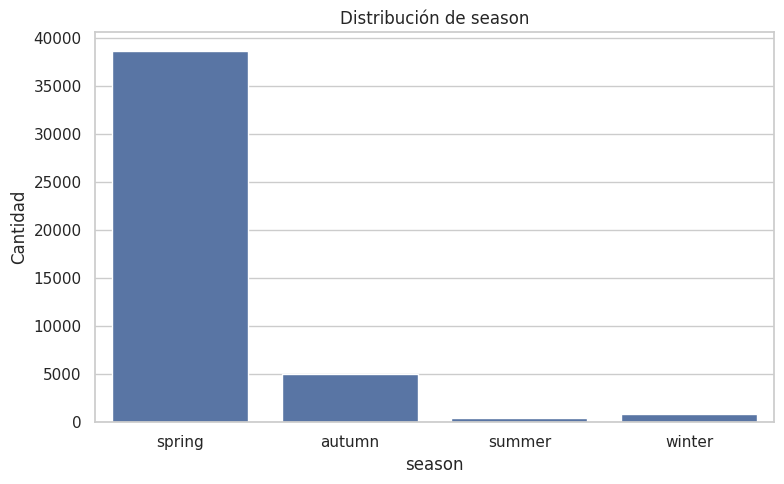

In [ ]:
col = "season"

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=col)

plt.title(f"Distribución de {col}")
plt.xlabel(col)
plt.ylabel("Cantidad")

plt.tight_layout()
plt.show()


>Interpretacion: Qué se ve

*   Spring domina: 38.694 registros, el 86% del total.
*   Autumn es la segunda: 4.999 registros (11%), unas 8 veces menos que primavera.
*   Winter y summer son casi invisibles: 864 (1,9%) y 443 (1,0%). Winter tiene aproximadamente el doble que summer.

Por qué ocurre

*   Primavera (abril-mayo) es la ventana clásica del Everest: viento más débil en la cumbre y temperaturas más tolerables, justo antes del monzón.
*   Otoño es la ventana secundaria, posterior al monzón.
*   En verano el monzón trae nieve, avalanchas y mala visibilidad.
*   En invierno hay frío extremo y vientos muy fuertes. Por eso casi nadie intenta subir en esas épocas.


### Columna `route`


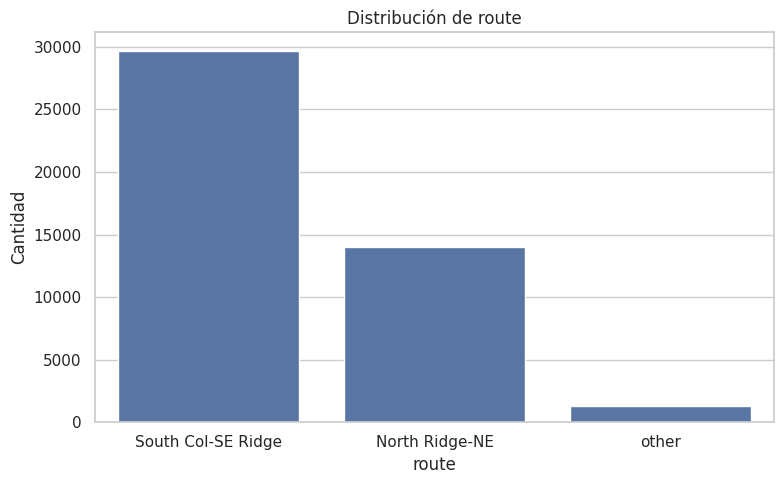

In [ ]:
col = "route"

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=col)

plt.title(f"Distribución de {col}")
plt.xlabel(col)
plt.ylabel("Cantidad")

plt.tight_layout()
plt.show()

>Interpretacion: La cantidad de expediciones según la ruta elegida para subir al Everest.

Ruta más popular: La gran mayoría de los escaladores eligen la ruta South Col-SE Ridge (Col Sudoeste), superando las 29.000 expediciones.

Segunda opción: Le sigue la ruta North Ridge-NE (Noreste) con cerca de 14.000.

Minoría: Las demás rutas (other) casi no se usan en comparación con las dos principales.



### Columna `age`


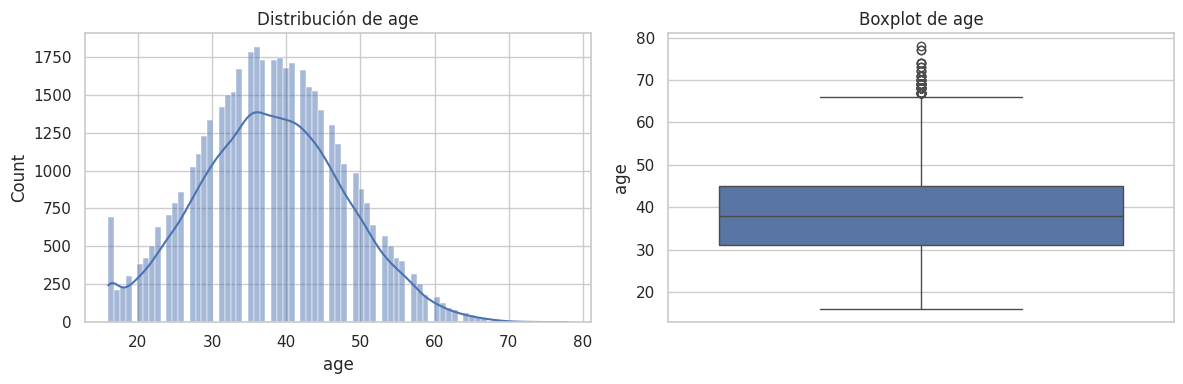

In [ ]:
col = "age"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma
sns.histplot(df[col], kde=True, ax=axes[0])
axes[0].set_title(f"Distribución de {col}")

# Boxplot
sns.boxplot(y=df[col], ax=axes[1])
axes[1].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

>Interpretacion: Rango principal (Campana): La mayoría de los escaladores se concentran entre los 30 y los 45 años (siendo el pico máximo alrededor de los 35-38 años).

Casos extremos (Outliers): El gráfico de caja (boxplot) muestra algunos puntos arriba de los 65-70 años, lo que indica que hay escaladores de edad muy avanzada, pero son casos minoritarios o excepciones. (117 filas)

### Columna `years_climbing`

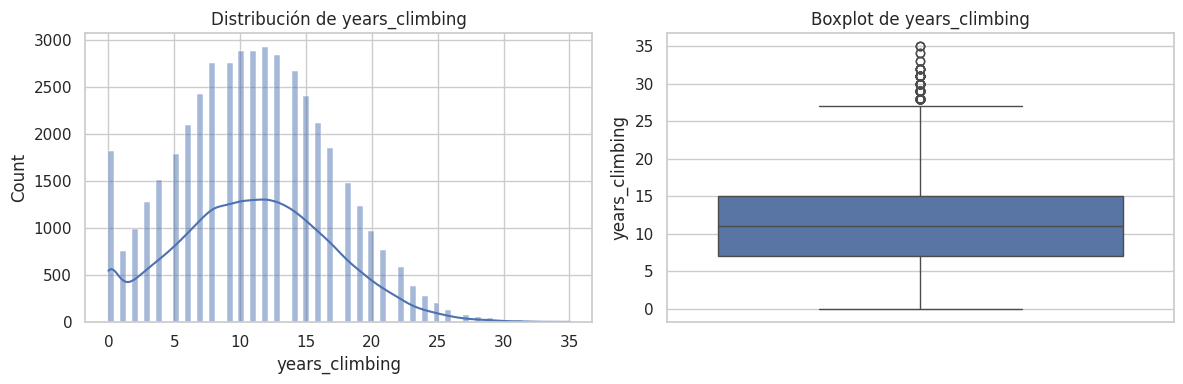

In [ ]:
col = "years_climbing"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma
sns.histplot(df[col], kde=True, ax=axes[0])
axes[0].set_title(f"Distribución de {col}")

# Boxplot
sns.boxplot(y=df[col], ax=axes[1])
axes[1].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

> Intepretacion: La gran mayoría de los escaladores poseen entre 7 y 15 años de experiencia en montaña (con el punto más alto alrededor de los 11-12 años).

> Casos particulares: Hay un pequeño grupo con 0 o pocos años (principiantes o personal de soporte), y en el boxplot se ven algunos valores atípicos (outliers) superiores a los 27 años (149 filas), que corresponden a montañistas veteranos de larga trayectoria.

### Columna `prior_8000m_peaks`


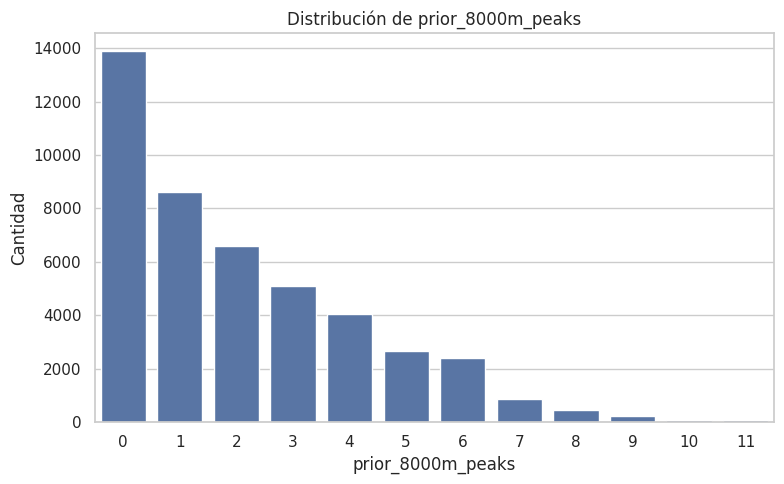

In [ ]:
col = "prior_8000m_peaks"

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=col)

plt.title(f"Distribución de {col}")
plt.xlabel(col)
plt.ylabel("Cantidad")

plt.tight_layout()
plt.show()

> La gran mayoría (0 a 3): La inmensa mayoría de los registros corresponden a escaladores con pocas o ninguna cumbre previa de 8.000 metros (el pico más alto está en 0). Esto indica que muchos se enfrentan a este nivel de exigencia por primera vez o tienen experiencia en montañas más bajas.

> Casos excepcionales: El gráfico de caja muestra que la mediana está en 1, y los puntos superiores (valores atípicos) llegan hasta las 11 cumbres previas, representando a montañistas de élite muy experimentados.

### Columna `prior_everest_attempts`


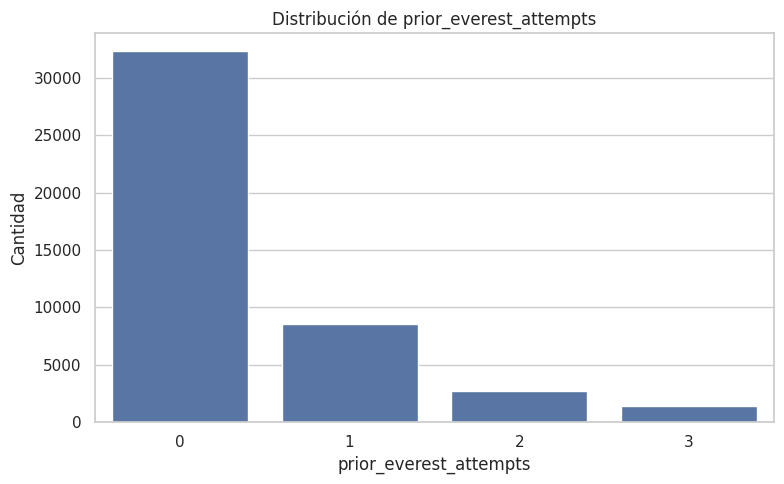

In [ ]:
col = "prior_everest_attempts"

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=col)

plt.title(f"Distribución de {col}")
plt.xlabel(col)
plt.ylabel("Cantidad")

plt.tight_layout()
plt.show()

> Mayoría en 0 (Primer intento): La gran mayoría de los registros (más de 30.000) corresponden a personas que están haciendo su primer intento histórico en el Everest.

>Minoría con experiencia previa: Los valores de 1, 2 o 3 intentos previos van disminuyendo drásticamente. Muestra que pocos escaladores reintentan la montaña múltiples veces tras no haber tenido éxito antes.

### Columna `highest_prev_altitude_m`

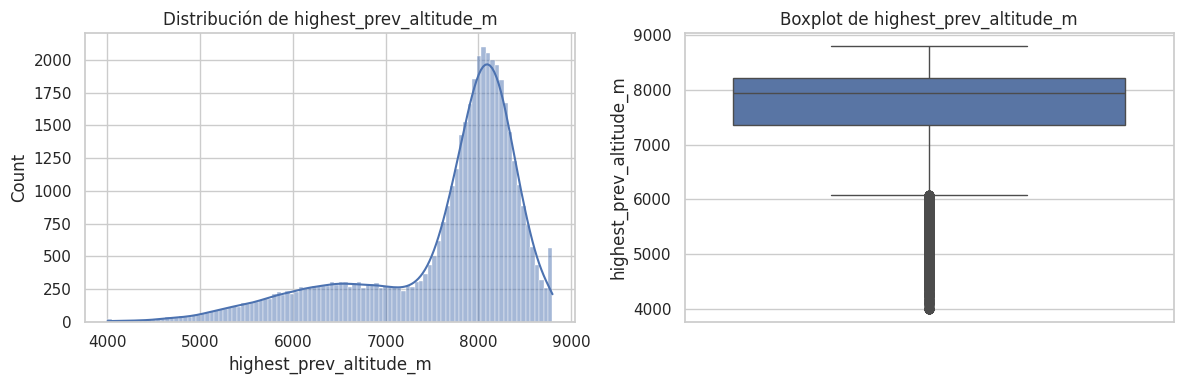

In [ ]:
col = "highest_prev_altitude_m"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma
sns.histplot(df[col], kde=True, ax=axes[0])
axes[0].set_title(f"Distribución de {col}")

# Boxplot
sns.boxplot(y=df[col], ax=axes[1])
axes[1].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

> Distribución asimétrica a la izquierda: la mayoría de los valores se concentran entre ~7.500 y 8.500 m, con un pico claro cerca de los 8.000–8.200 m.

> Mediana y rango: la mediana está cerca de los 7.900 m. El 50% central de los datos va aproximadamente de 7.400 a 8.200 m. El máximo ronda los 8.800 m.

> Outliers: el boxplot marca como atípicos todos los valores por debajo de ~6.100 m. Son muchísimos puntos, así que no son errores aislados: es una subpoblación real con experiencia previa en altitudes menores.


### Columna `operator_tier`


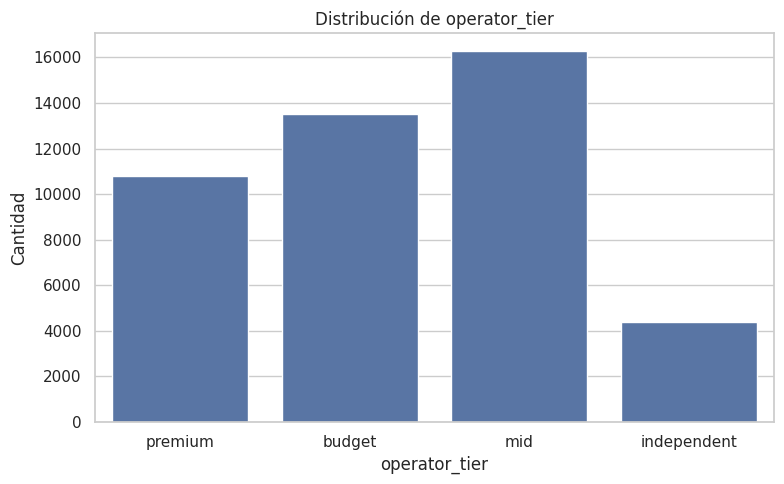

In [ ]:
col = "operator_tier"

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=col)

plt.title(f"Distribución de {col}")
plt.xlabel(col)
plt.ylabel("Cantidad")

plt.tight_layout()
plt.show()

>Mayoría en nivel medio y económico: La mayor parte de las expediciones eligen operadores de nivel mid (medio) y budget (económico).

>Operadores premium: También tienen una presencia importante (cerca de 11.000 registros).

>Independientes: Son la minoría, lo que indica que casi todos los escaladores prefieren contratar algún tipo de servicio de guía u operador logístico organizado.


### Columna `team_size`


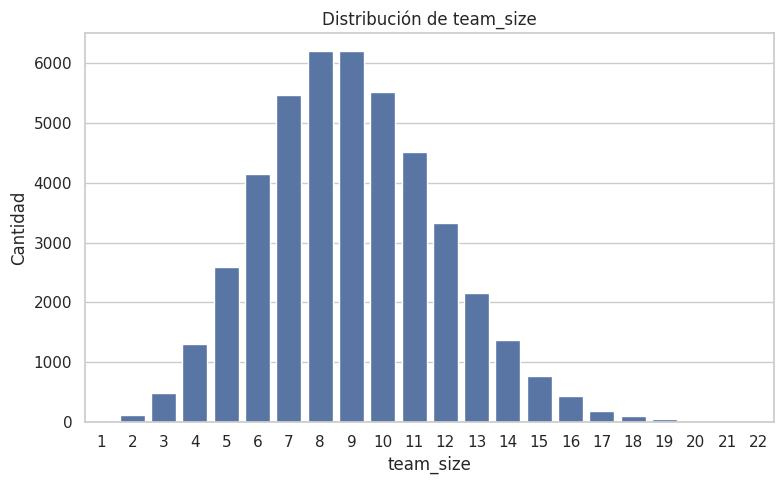

In [ ]:
col = "team_size"

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=col)

plt.title(f"Distribución de {col}")
plt.xlabel(col)
plt.ylabel("Cantidad")

plt.tight_layout()
plt.show()

>El gráfico muestra que el tamaño de los equipos se concentra principalmente entre 7 y 10 integrantes, siendo 8 y 9 personas los tamaños más frecuentes. A partir de 10 integrantes, la frecuencia disminuye progresivamente, mientras que los equipos muy pequeños o muy grandes son poco frecuentes.

>En general, la distribución presenta una mayor concentración en tamaños intermedios, con algunos casos extremos de equipos de aproximadamente 2 a 19 integrantes.

### Columna `sherpa_ratio`

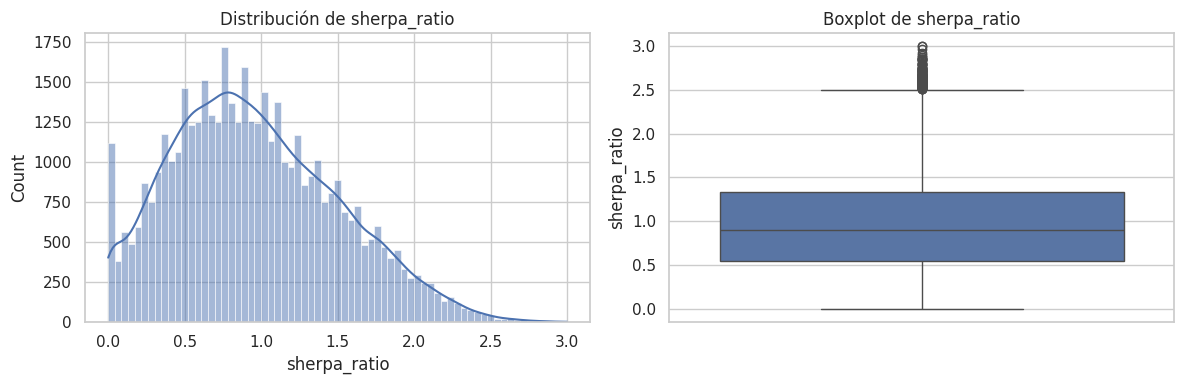

In [ ]:
col = "sherpa_ratio"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma
sns.histplot(df[col], kde=True, ax=axes[0])
axes[0].set_title(f"Distribución de {col}")

# Boxplot
sns.boxplot(y=df[col], ax=axes[1])
axes[1].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

> La mayoría de los valores se concentran entre ~0,5 y 1,3, con el pico alrededor de 0,8. Hay una cola larga hacia valores altos, hasta ~3,0.

> Pico en 0: hay una barra aislada en 0. Probablemente son expediciones sin sherpas.

>Outliers: el boxplot marca como atípicos los valores por encima de ~2,5. Son pocos y se ven continuos, así que parecen casos legítimos de expediciones con muchos sherpas por cliente, no errores.

### Columna `uses_oxygen`

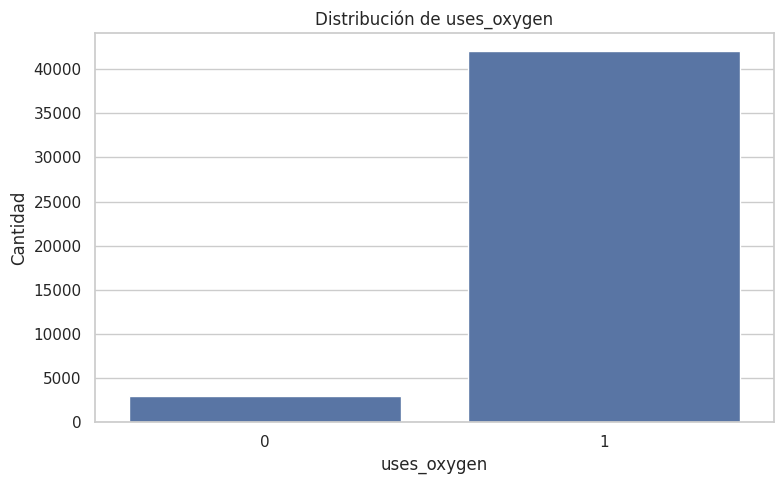

In [ ]:
col = "uses_oxygen"

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=col)

plt.title(f"Distribución de {col}")
plt.xlabel(col)
plt.ylabel("Cantidad")

plt.tight_layout()
plt.show()

> Uso masivo (1): La inmensa mayoría de las expediciones (más de 40.000 registros) sí utilizan oxígeno suplementario para afrontar las alturas extremas de la montaña.

> Minoría sin oxígeno (0): Los que intentan subir sin oxígeno son una pequeña minoría (menos de 3.000), lo que refleja el altísimo riesgo que implica prescindir de él en la zona de la muerte.

### Columna `o2_start_altitude_m`

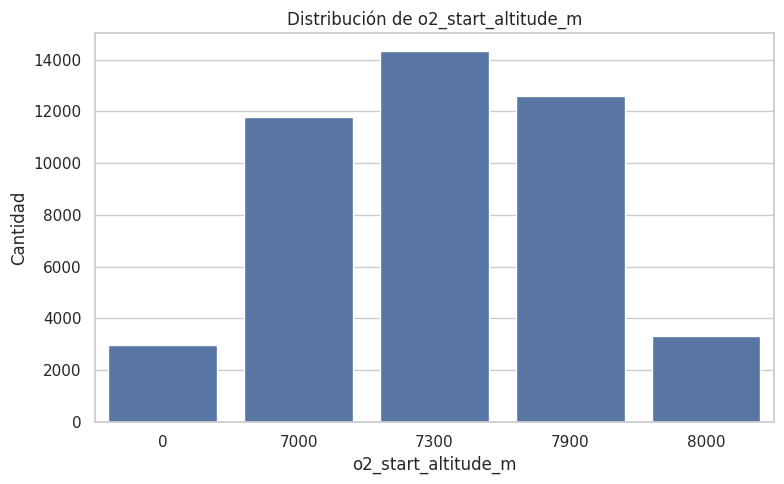

In [ ]:
col = "o2_start_altitude_m"

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=col)

plt.title(f"Distribución de {col}")
plt.xlabel(col)
plt.ylabel("Cantidad")

plt.tight_layout()
plt.show()

> Zona estándar de inicio (7.000 a 7.900 m): La inmensa mayoría de las personas comienza a usar oxígeno entre los 7.000 y los 7.900 metros, destacándose los 7.300 m con más de 14.000 registros como la cota más habitual.   

> Uso tardío (8.000 m): Alrededor de 3.200 escaladores esperan a llegar al Collado Sur o la entrada de la "zona de la muerte" (8.000 m) para abrir el flujo de oxígeno.   

> Sin oxígeno suplementario (0 m): Cerca de 3.000 registros marcan 0 metros, representando los intentos de ascenso en estilo deportivo sin botellas de oxígeno.

### Columna `days_acclimatizing`


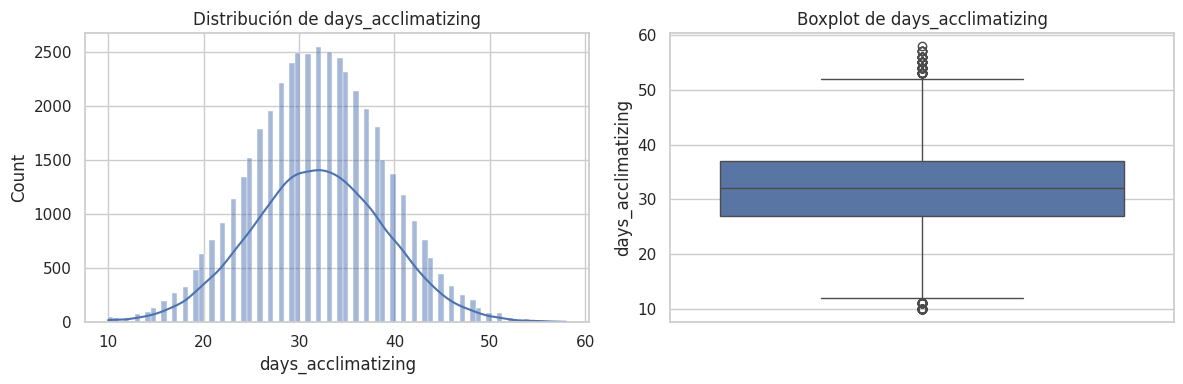

In [ ]:
col = "days_acclimatizing"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma
sns.histplot(df[col], kde=True, ax=axes[0])
axes[0].set_title(f"Distribución de {col}")

# Boxplot
sns.boxplot(y=df[col], ax=axes[1])
axes[1].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

> La gran mayoría de las expediciones realizan una aclimatación que dura entre 30 y 35 días (con un pico marcado alrededor de los 32-33 días).

> El boxplot muestra una distribución muy ordenada y simétrica, con la mayoría concentrada entre los 27 y 37 días, y casos aislados que van desde los 10 hasta casi los 60 días según la estrategia de cada equipo.

### Columna `camps_established`

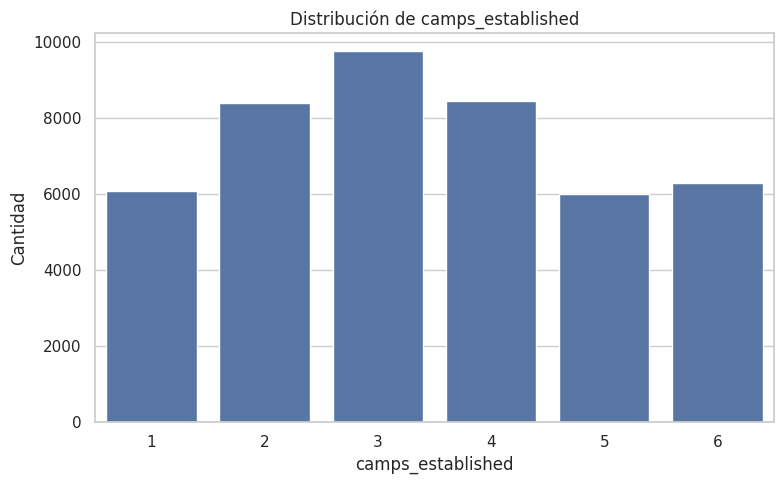

In [ ]:
col = "camps_established"

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=col)

plt.title(f"Distribución de {col}")
plt.xlabel(col)
plt.ylabel("Cantidad")

plt.tight_layout()
plt.show()

> Estrategia y avance más común (2 a 4 campamentos): La mayor parte de los registros se sitúa entre 2 y 4 campamentos montados, destacándose 3 campamentos con casi 10.000 observaciones como el valor más frecuente. Esto refleja la progresión intermedia habitual antes de arrancar hacia la cumbre o las cancelaciones por mal tiempo en fases medias.   

> Extremos logísticos (1 campamento vs. 5 o 6): Alrededor de 6.000 expediciones solo alcanzaron a montar 1 campamento, mientras que entre 5 y 6 campamentos (unas 6.000 a 6.300 expediciones) representan rutas más largas o con despliegues logísticos pesados.

### Columna `summit_window_days`

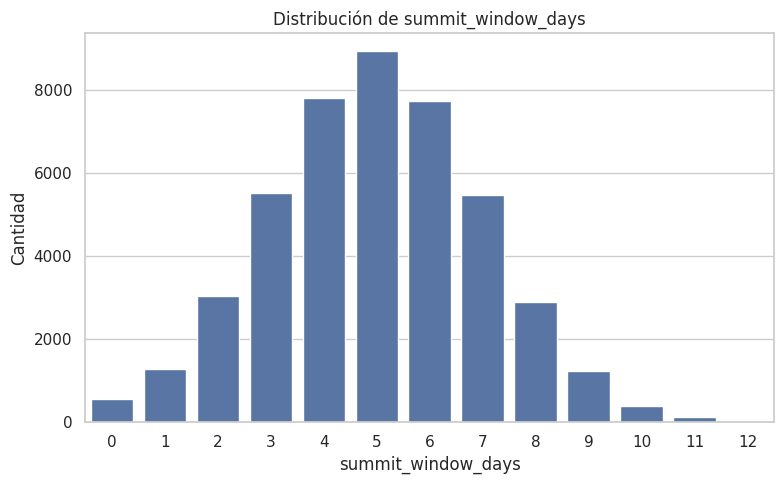

In [ ]:
col = "summit_window_days"

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=col)

plt.title(f"Distribución de {col}")
plt.xlabel(col)
plt.ylabel("Cantidad")

plt.tight_layout()
plt.show()

> Rango principal (4 a 6 días): La mayoría de las expediciones cuentan con una ventana de buen tiempo de entre 4 y 6 días (siendo 5 días el pico más frecuente).


### Columna `weather_score`

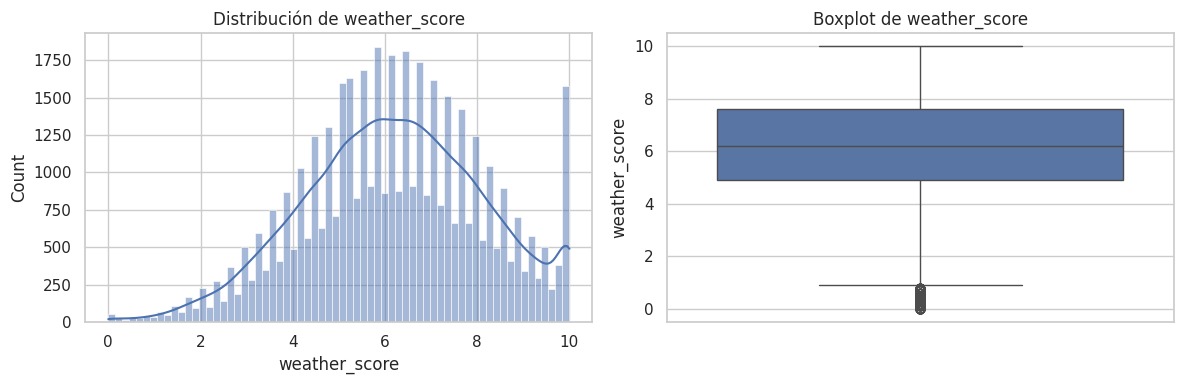

In [ ]:
col = "weather_score"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma
sns.histplot(df[col], kde=True, ax=axes[0])
axes[0].set_title(f"Distribución de {col}")

# Boxplot
sns.boxplot(y=df[col], ax=axes[1])
axes[1].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

> La gran mayoría de los ascensos se realizan con condiciones meteorológicas moderadas a favorables.

>Pico en clima perfecto (10): El histograma muestra una acumulación marcada en el valor máximo de 10 (más de 1.500 casos), correspondiente a las codiciadas ventanas climáticas ideales de vientos calmos y cielo despejado que los equipos esperan para el asalto a la cima.   

>Valores atípicos inferiores (0 a 1): En el diagrama de caja se observan outliers cerca de 0, reflejando expediciones atrapadas por tormentas imprevistas o condiciones climáticas extremadamente severas.

### Columna `jetstream_risk`

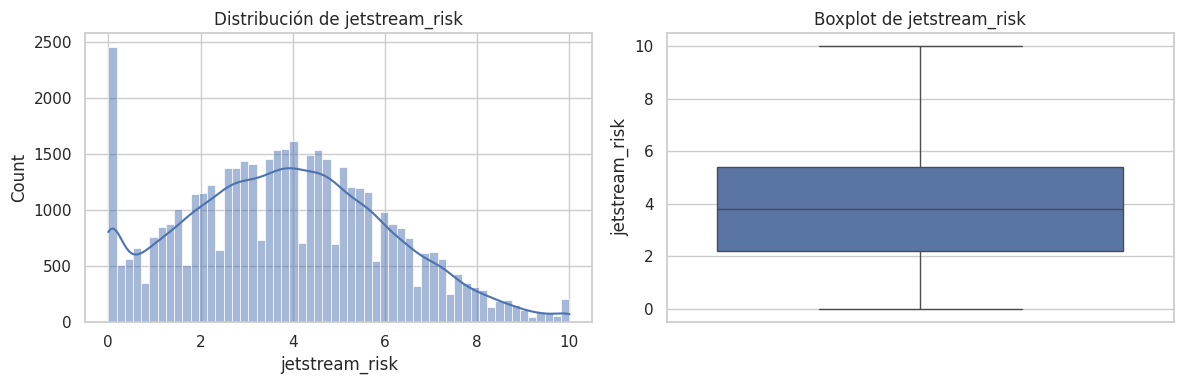

In [ ]:
col = "jetstream_risk"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma
sns.histplot(df[col], kde=True, ax=axes[0])
axes[0].set_title(f"Distribución de {col}")

# Boxplot
sns.boxplot(y=df[col], ax=axes[1])
axes[1].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

> Rango habitual (2 a 5): La mayoría de los registros se concentran en un nivel de riesgo moderado que va desde los valores 2 hasta los 5 (con el pico más alto cerca de 4).

> Casos extremos: Hay un grupo importante con riesgo casi nulo (cercano a 0), y el boxplot muestra que la escala llega de manera uniforme hasta un riesgo máximo de 10, abarcando todas las variaciones meteorológicas posibles.

### Columna `queue_minutes_above_8000`


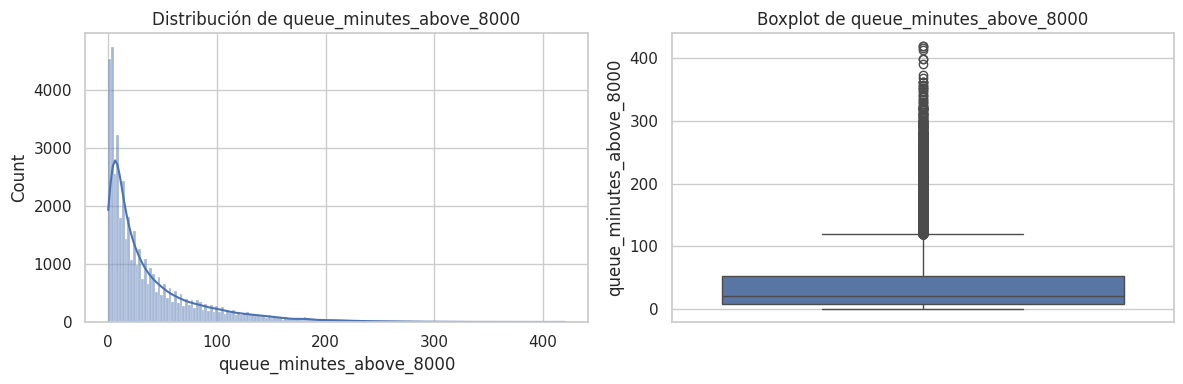

In [ ]:
col = "queue_minutes_above_8000"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma
sns.histplot(df[col], kde=True, ax=axes[0])
axes[0].set_title(f"Distribución de {col}")

# Boxplot
sns.boxplot(y=df[col], ax=axes[1])
axes[1].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

> La gran mayoría de los valores se concentran cerca de 0-30 minutos, con el pico en los primeros minutos (~4.500-4.700 registros).


>Outliers: el boxplot marca como atípicos todos los valores por encima de ~120 minutos. Son muchos y forman una columna continua, no puntos aislados. Es esperable en una variable de tiempos de espera: la mayoría pasa rápido, pero en días de congestión (ventanas de buen clima con muchas cordadas) las colas se vuelven larguísimas. Son casos reales, no errores.

# 8. Análisis de las filas del dataset

Se verifican tres aspectos:

1. valores nulos;
2. registros duplicados;
3. identificadores duplicados;
4. relaciones lógicas entre variables;
5. filas no utiles para el analisis.

In [ ]:
# Nulos
print("Cantidad total de valores nulos:", df.isna().sum().sum())

# Filas duplicadas
print("Filas duplicadas:", df.duplicated().sum())

# IDs duplicados
print("IDs duplicados:", df["climber_id"].duplicated().sum())

Cantidad total de valores nulos: 0
Filas duplicadas: 0
IDs duplicados: 0


In [ ]:
# ======================
# Eliminación de filas
# ======================

filas_a_eliminar = (
    ((df["uses_oxygen"] == 0) & (df["o2_start_altitude_m"] > 0)) |
    ((df["uses_oxygen"] == 1) & (df["o2_start_altitude_m"] == 0)) |
    (df["age"] < 16) |
    (df["years_climbing"] > df["age"] - 10) |
    (df["is_hired_staff"] == 1) |
    (df["age"] > 60) |
    (df["years_climbing"] > 25)
    )



print("Inconsistencias por oxígeno:", (
    ((df["uses_oxygen"] == 0) & (df["o2_start_altitude_m"] > 0)) |
    ((df["uses_oxygen"] == 1) & (df["o2_start_altitude_m"] == 0))
).sum())

print("Edad menor a 16:", (df["age"] < 16).sum())

print("Experiencia incompatible con edad:", (
    df["years_climbing"] > df["age"] - 10
).sum())

print("Personal contratado:", (df["is_hired_staff"] == 1).sum())

print("Total de filas a eliminar:", filas_a_eliminar.sum())

## edad mayor a 60
print("Casos edad mayor a 60 años:", (
    ((df["age"] > 60) )
).sum())

print("Casos experiencia escalando mayor a 25 años:", (
    ((df["years_climbing"] > 25) )
).sum())


df = df[~filas_a_eliminar].copy()

print("Filas restantes:", len(df))

Inconsistencias por oxígeno: 0
Edad menor a 16: 0
Experiencia incompatible con edad: 3003
Personal contratado: 13508
Total de filas a eliminar: 16066
Casos edad mayor a 60 años: 531
Casos experiencia escalando mayor a 25 años: 357
Filas restantes: 28934


### Interpretación del analisis de las filas

No se encontraron:

- valores nulos;
- filas duplicadas;
- identificadores duplicados;
- inconsistencias entre `uses_oxygen` y `o2_start_altitude_m`;
- registros de edades menores de 16 años.

**Inconsistencias:**
Se observan algunos casos donde los años de escalada son elevados respecto de la edad. Estos registros se eliminaran del dataset final.



**Filas no utiles para el analisis:** ambién se eliminarán aquellas filas cuyo valor en `is_hired_staff = 1`, correspondientes a personal de apoyo contratado para la expedición. Estas observaciones no se consideran dentro de la población objetivo del modelo, ya que la predicción busca estimar la probabilidad de cumbre de los **escaladores que intentan alcanzar la cima**, excluyendo al personal contratado que forma parte de los equipos de apoyo. (13.508)

### 8.1 Analisis de años escalando y edad despues de eliminar filas


#### Age

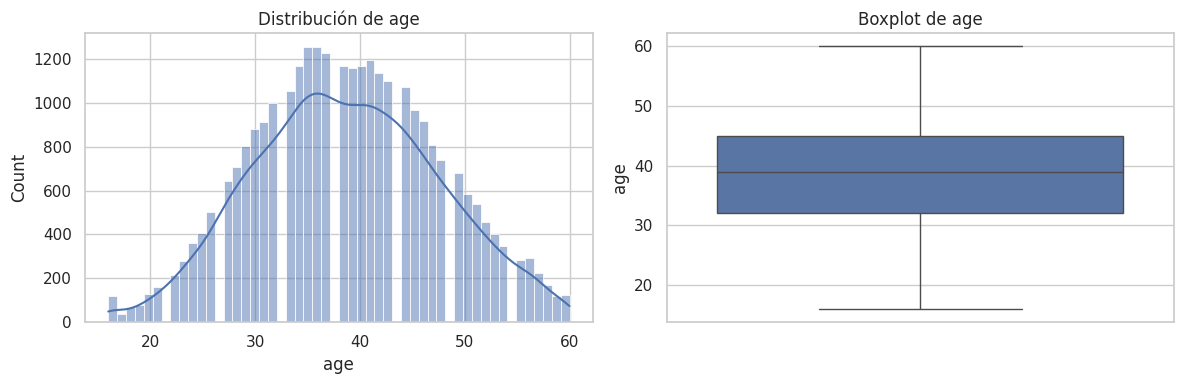

In [ ]:
col = "age"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma
sns.histplot(df[col], kde=True, ax=axes[0])
axes[0].set_title(f"Distribución de {col}")

# Boxplot
sns.boxplot(y=df[col], ax=axes[1])
axes[1].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

### years_climbing

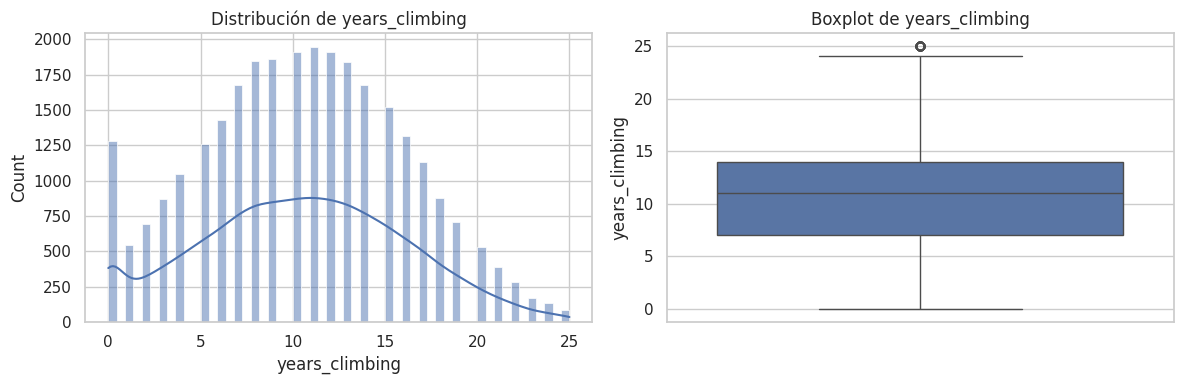

In [ ]:
col = "years_climbing"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma
sns.histplot(df[col], kde=True, ax=axes[0])
axes[0].set_title(f"Distribución de {col}")

# Boxplot
sns.boxplot(y=df[col], ax=axes[1])
axes[1].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

# 9. Identificación de columnas que deben eliminarse
Para una predicción ex ante, una variable es válida si la información que representa estaría disponible antes de comenzar la expedición. Por este motivo, se eliminan las columnas:

`climber_id`
Es un identificador único. No representa una característica útil del escalador y podría hacer que el modelo memorice identificadores.

`turnaround_reason`
Representa el motivo por el que una expedición se dio vuelta. Es información posterior al comienzo de la expedición y, en algunos casos, prácticamente determina el resultado.

`serious_incident`
Indica si ocurrió un incidente grave. También es información que se conoce durante o después del desarrollo de la expedición.

Incluir las dos últimas variables produciría fuga de información (data leakage).

Ademas, considerando que nuestro objetivo son los escaladores que tienen como objetivo llegar a la cima, y no aquellos participantes que forman parte del equipo de ayuda, eliminamos la columna `is_hired_staff`


In [ ]:
# ==========================================
# Eliminación de columnas no utilizables
# ==========================================

columnas_eliminar = [
    "climber_id",
    "is_hired_staff",
    "turnaround_reason",
    "serious_incident"
]

df_etl = df.drop(columns=columnas_eliminar).copy()

print("Dimensiones antes:", df.shape)
print("Dimensiones después:", df_etl.shape)
print("\nVariables conservadas:")
display(pd.DataFrame({"variable": df_etl.columns}))

Dimensiones antes: (28934, 25)
Dimensiones después: (28934, 21)

Variables conservadas:


,variable
0,year
1,season
2,route
3,age
4,sex
5,years_climbing
6,prior_8000m_peaks
7,prior_everest_attempts
8,highest_prev_altitude_m
9,operator_tier


# 10. Codificación de variables categóricas

Los algoritmos de aprendizaje automático trabajan con variables numéricas. Sin embargo, no todas las variables categóricas deben convertirse asignando números arbitrarios.

Por ejemplo, transformar:

`route = North Ridge → 0`, `South Col → 1`, `other → 2`

podría hacer que el modelo interprete artificialmente que existe un orden entre las rutas.

Por este motivo se utiliza:

- **0/1** para variables binarias.
- **One-Hot Encoding** para variables categóricas nominales.

De esta forma cada categoría se representa mediante una columna numérica binaria.

In [ ]:
# Variables binarias
df_etl["sex"] = df_etl["sex"].map({"F": 0, "M": 1})

# One-Hot Encoding para variables nominales
variables_onehot = [
    "season",
    "route",
    "operator_tier"
]

df_etl = pd.get_dummies(
    df_etl,
    columns=variables_onehot,
    prefix=variables_onehot,
    dtype=int
)

print("Dataset después de la codificación:")
display(df_etl.head())
print("\nTipos de datos:")
display(df_etl.dtypes.to_frame("tipo"))

Dataset después de la codificación:


,year,age,sex,years_climbing,prior_8000m_peaks,prior_everest_attempts,highest_prev_altitude_m,team_size,sherpa_ratio,uses_oxygen,o2_start_altitude_m,days_acclimatizing,camps_established,summit_window_days,weather_score,jetstream_risk,queue_minutes_above_8000,summited,season_autumn,season_spring,season_summer,season_winter,route_North Ridge-NE,route_South Col-SE Ridge,route_other,operator_tier_budget,operator_tier_independent,operator_tier_mid,operator_tier_premium
0,2025,56,1,15,0,1,5994,16,1.30,1,7000,29,6,5,10.0,1.3,120,0,0,1,0,0,0,1,0,0,0,0,1
1,2020,47,1,7,0,1,6434,9,1.51,1,7900,27,4,5,4.8,4.7,26,1,0,1,0,0,1,0,0,0,0,0,1
3,2024,50,0,12,3,0,8354,11,0.14,1,7000,35,2,6,5.9,3.0,45,0,0,1,0,0,0,1,0,1,0,0,0
4,2015,60,0,1,1,0,8014,9,1.52,1,7300,20,1,7,6.7,2.7,20,0,0,1,0,0,1,0,0,0,0,1,0
5,2011,28,1,17,1,1,8152,12,2.54,1,7900,33,5,5,4.1,5.7,13,1,0,1,0,0,0,1,0,0,0,0,1



Tipos de datos:


,tipo
year,int64
age,int64
sex,int64
years_climbing,int64
prior_8000m_peaks,int64
prior_everest_attempts,int64
highest_prev_altitude_m,int64
team_size,int64
sherpa_ratio,float64
uses_oxygen,int64


### Representación numérica obtenida

Las variables originales:

- `sex`
- `season`
- `route`
- `operator_tier`

quedan representadas únicamente mediante valores numéricos.

Por ejemplo, `season` genera columnas como:

- `season_spring`
- `season_autumn`
- `season_winter`
- `season_summer`

Cada una contiene `0` o `1`.

Esto evita asignar un orden artificial a las categorías.

# 11. Exportación del dataset final

El resultado de la etapa ETL es un dataset numérico, sin nulos, sin identificadores innecesarios y sin variables que produzcan fuga de información.

Este archivo será utilizado posteriormente para la etapa de modelado.

In [ ]:
# Guardar dataset limpio
output_file = "everest_dataset_limpio.csv"
df_etl.to_csv(output_file, index=False)

print(f"Archivo generado: {output_file}")
print(f"Filas: {df_etl.shape[0]:,}")
print(f"Columnas: {df_etl.shape[1]}")

Archivo generado: everest_dataset_limpio.csv
Filas: 28,934
Columnas: 29


# 12. Conclusiones de la etapa ETL
A partir del análisis realizado:

A partir del análisis realizado:

1. El dataset original contiene **45.000 registros y 25 variables**.
2. No se encontraron valores nulos.
3. No se encontraron filas duplicadas ni identificadores duplicados.
4. Se analizaron las variables categóricas y sus categorías posibles.
5. Se analizaron las variables numéricas mediante estadísticas, histogramas y boxplots.
6. Se detectaron posibles outliers mediante IQR, pero no se eliminaron automáticamente porque pueden representar casos reales.
7. No se detectaron contradicciones relevantes en las reglas de consistencia analizadas.
8. Se eliminaron `climber_id`, `year`, `turnaround_reason` y `serious_incident`.
9. Se eliminaron las filas cuyo valor `is_hired_staff = 1`
10. `turnaround_reason` y `serious_incident` se eliminaron especialmente para evitar **data leakage**, ya que no corresponden a información disponible para una predicción ex ante.
11. Las variables categóricas se transformaron a variables numéricas mediante codificación binaria y One-Hot Encoding.
12. Se obtuvo un dataset final preparado para la siguiente etapa: **selección de características, división train/test y modelado predictivo**.
